# Hysteresis repeatability across contractions — MUedit filter-tracking (TA, S1–S8)

Reviewer point: hysteresis (DRT/RT − 1) was averaged across contractions. This notebook tracks the **same** motor unit across the 10–80 % MVC contractions using the **paper's own method** (Avrillon et al. 2024 / MUedit `MUdict.m`), then shows how each unit's hysteresis varies across contractions.

**Tracking = filter reconstruction + reapplication + spike coincidence** (not MUAP-waveform correlation, which aliases units):
1. `getMUfilters` — reconstruct each unit's separation filter from raw EMG + its discharge times (extend → spike-triggered average).
2. `getPulseT` — re-apply that filter to another contraction's EMG (`s = (STAᵀ·C⁻¹)·eSIG`), peak-detect.
3. Match by **discharge-time coincidence** (RoA ≥ 0.3), building a growing per-subject dictionary.

**Validation:** average each tracked unit's per-contraction hysteresis and compare to the reported spreadsheet (`Data - Hysteresis .xlsx`). **7/8 subjects match** (KS p > 0.05); **S6** does not — its local decomposition differs from the reported values even before tracking, so it can't be reproduced from these files.

In [1]:
# %% Config, imports, style
%matplotlib inline
import os, glob, re, pickle, time
import numpy as np, scipy.io as sio, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.ndimage import maximum_filter1d
from scipy.stats import ks_2samp, spearmanr

plt.rcParams.update({"font.family":"sans-serif","font.sans-serif":["Arial","Helvetica","DejaVu Sans"],
                     "axes.spines.top":False,"axes.spines.right":False,"axes.linewidth":0.9,"figure.dpi":110})

BASE="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_subjects_Avrillonetal"
RAW=os.path.join(BASE,"RawEMG"); XLSX=os.path.join(BASE,"Data - Hysteresis .xlsx")
CACHE="/Users/nmt121/Desktop/Repositories/Motoneuron_Model/notebooks/.muedit_tracks.pkl"
SUBJECTS=list(range(1,9)); LEVELS=["10","20","30","40","50","60","70","80"]; FS=2048
THR=0.3; JIT=10; NBEXT=1500; FAIL={6}   # S6 not reproducible from these files
print("config ok")

config ok


### MUedit tracking functions (ported from simonavrillon/MUdictionnary)

In [2]:
# %% Ported MUedit pipeline
def resolve(subj,lvl):
    c=glob.glob(f"{RAW}/S{subj}_{lvl}_DF*.mat")
    if not c: return None
    n=[x for x in c if "edited_new" in x]; return n[0] if n else sorted(c)[0]
def extend(eY,ex):
    r,cN=eY.shape; out=np.zeros((r*ex,cN+ex-1),np.float32)
    for m in range(ex): out[m*r:(m+1)*r,m:cN+m]=eY
    return out
def native_units(m,g):
    dt=np.atleast_2d(m['edition'].Dischargetimes); n=np.asarray(m['signal'].data).shape[1]; out=[]
    if g>=dt.shape[0]: return out
    for j in range(dt.shape[1]):
        st=np.atleast_1d(np.asarray(dt[g,j])).ravel(); st=st[np.isfinite(st)].astype(int)-1
        st=st[(st>=0)&(st<n)]
        if st.size>=5: out.append(st)
    return out
def level_step(emg,nat,Dfil):
    ex=round(NBEXT/emg.shape[0]); eS=extend(emg,ex); T=emg.shape[1]
    Fn=np.zeros((eS.shape[0],len(nat)),np.float32)
    for i,st in enumerate(nat): Fn[:,i]=eS[:,st].sum(1)         # getMUfilters (STA)
    reapp=[]
    if Dfil is not None and Dfil.shape[1]>0:
        C=(eS@eS.T)/eS.shape[1]; iC=np.linalg.pinv(C).astype(np.float32)
        S=(Dfil.T@iC)@eS                                        # getPulseT: sources
        for k in range(S.shape[0]):
            pt=S[k,:T]; pt=pt*np.abs(pt)
            pk,_=find_peaks(pt,distance=round(FS*0.02))
            if len(pk)<3: reapp.append(np.array([],int)); continue
            vals=pt[pk]; c=np.array([vals.min(),vals.max()])
            for _ in range(12):
                lab=(np.abs(vals[:,None]-c[None,:])).argmin(1)
                for tt in (0,1):
                    if (lab==tt).any(): c[tt]=vals[lab==tt].mean()
            reapp.append(pk[lab==int(np.argmax(c))])
        del C,iC,S
    del eS; return Fn,reapp
def match(reapp,nat,T):
    nD,nN=len(reapp),len(nat)
    if nD==0 or nN==0: return []
    nb=np.zeros((nN,T),np.float32)
    for j,sp in enumerate(nat):
        s=sp[(sp>=0)&(sp<T)]; nb[j,s]=1
    nd=maximum_filter1d(nb,size=2*JIT+1,axis=1)
    rb=np.zeros((nD,T),np.float32)
    for i,sp in enumerate(reapp):
        s=sp[(sp>=0)&(sp<T)];
        if len(s): rb[i,s]=1
    common=rb@nd.T
    lenR=np.array([len(s) for s in reapp])[:,None]; lenN=np.array([len(s) for s in nat])[None,:]
    roa=common/np.maximum(np.maximum(lenR,lenN),1)
    pairs=[]; ud=set(); un=set()
    for flat in np.argsort(-roa,axis=None):
        i,j=divmod(int(flat),nN)
        if roa[i,j]<THR: break
        if i in ud or j in un: continue
        ud.add(i); un.add(j); pairs.append((i,j))
    return pairs
def process_subject(subj):
    files={lvl:resolve(subj,lvl) for lvl in LEVELS if resolve(subj,lvl)}
    mats={lvl:sio.loadmat(f,squeeze_me=True,struct_as_record=False) for lvl,f in files.items()}
    present=sorted(mats,key=int)
    data={lvl:np.asarray(mats[lvl]['signal'].data,np.float32) for lvl in present}
    force={lvl:np.asarray(mats[lvl]['signal'].path,float) for lvl in present}
    ngrid=min(data[lvl].shape[0]//64 for lvl in present); chains=[]
    for g in range(ngrid):
        natc={lvl:native_units(mats[lvl],g) for lvl in present}; D=[]
        for lvl in present:
            nat=natc[lvl]
            if not nat: continue
            emg=data[lvl][g*64:(g+1)*64,:]; T=emg.shape[1]
            Dfil=np.stack([u['filter'] for u in D],axis=1) if D else None
            Fn,reapp=level_step(emg,nat,Dfil); matched=set()
            if D:
                for di,ni in match(reapp,nat,T):
                    D[di]['levels'][lvl]=ni; D[di]['filter']=Fn[:,ni]; matched.add(ni)
            for ni in range(len(nat)):
                if ni not in matched: D.append(dict(filter=Fn[:,ni],levels={lvl:ni}))
        for u in D:
            rec={}
            for lvl,ni in u['levels'].items():
                sp=natc[lvl][ni]; f=force[lvl]; rt=f[sp[0]]; drt=f[sp[-1]]
                rec[int(lvl)]=dict(RT=float(rt),DRT=float(drt),
                                   hyst=float(drt/rt-1) if abs(rt)>1e-2 else np.nan,n=int(sp.size))
            chains.append(dict(subject=subj,grid=g,levels=rec))
    return chains
print("pipeline defined")

pipeline defined


### Run (or load) the tracking — cached; first run ~10 min

In [3]:
# %% Track all subjects (cached to notebooks/.muedit_tracks.pkl)
if os.path.exists(CACHE):
    tracks=pickle.load(open(CACHE,"rb")); print("loaded cached tracks")
else:
    tracks={}
    for s in SUBJECTS:
        t=time.time(); tracks[s]=process_subject(s)
        print(f"  S{s}: {len(tracks[s])} units ({sum(len(c['levels'])>=2 for c in tracks[s])} multi-level) {time.time()-t:.0f}s",flush=True)
    pickle.dump(tracks,open(CACHE,"wb"))
print("units per subject:", {s:len(tracks[s]) for s in SUBJECTS})

loaded cached tracks
units per subject: {1: 234, 2: 286, 3: 136, 4: 169, 5: 122, 6: 130, 7: 187, 8: 92}


### Validation — tracked-unit-average hysteresis vs the reported spreadsheet

In [4]:
# %% Read spreadsheet hysteresis + KS validation
import zipfile, xml.etree.ElementTree as ET
def read_xlsx_hyst(path):
    z=zipfile.ZipFile(path); NS={'a':'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    sst=[]; t=ET.fromstring(z.read('xl/sharedStrings.xml'))
    for si in t.findall('a:si',NS): sst.append("".join(n.text or "" for n in si.iter('{%s}t'%NS['a'])))
    sh=ET.fromstring(z.read('xl/worksheets/sheet1.xml')); G={}
    for row in sh.iter('{%s}row'%NS['a']):
        for c in row.findall('a:c',NS):
            ref=c.get('r'); col=re.match(r'[A-Z]+',ref).group(); r=int(re.search(r'\d+',ref).group()); v=c.find('a:v',NS)
            if v is not None: G[(r,col)]=sst[int(v.text)] if c.get('t')=='s' else v.text
    hcol={1:'C',2:'F',3:'I',4:'L',5:'O',6:'R',7:'U',8:'X'}; out={}
    for s,col in hcol.items():
        vals=[]
        for r in range(3,222):
            try: vals.append(float(G.get((r,col))))
            except: pass
        out[s]=np.array(vals)
    return out
xlh=read_xlsx_hyst(XLSX)
rows=[]
for s in SUBJECTS:
    meanH=[np.mean([lv[l]["hyst"] for l in lv if np.isfinite(lv[l]["hyst"])])
           for c in tracks[s] for lv in [c["levels"]] if sum(np.isfinite(lv[l]["hyst"]) for l in lv)>=2]
    meanH=np.array([x for x in meanH if np.isfinite(x)])
    cl=lambda a:np.clip(a,-1,3); p=ks_2samp(cl(xlh[s]),cl(meanH)).pvalue
    rho=[spearmanr(sorted(c["levels"]),[c["levels"][l]["RT"] for l in sorted(c["levels"])]).statistic
         for c in tracks[s] if len(c["levels"])>=3]
    rows.append(dict(subject=f"S{s}", n_units=len(meanH), xlsx_median=round(np.median(xlh[s]),3),
                     my_median=round(np.median(meanH),3), KS_p=round(p,3),
                     RT_level_rho=round(np.nanmedian(rho),2), verdict="MATCH" if p>0.05 else "differs"))
val=pd.DataFrame(rows); print(val.to_string(index=False))
print(f"\n{(val.KS_p>0.05).sum()}/8 subjects match the reported values.")
print("RT_level_rho > 0 => the same unit recruits later at higher force (real level-dependence, not tracking error).")

subject  n_units  xlsx_median  my_median  KS_p  RT_level_rho verdict
     S1      150        0.088      0.086 0.695          0.50   MATCH
     S2      163       -0.231     -0.230 0.456          0.50   MATCH
     S3       52       -0.103     -0.224 0.293          1.00   MATCH
     S4       82       -0.088     -0.099 0.736          0.40   MATCH
     S5       59       -0.044     -0.053 0.599          0.40   MATCH
     S6       44       -0.280     -0.170 0.000          0.85 differs
     S7       73        0.136      0.167 0.685          0.00   MATCH
     S8       34       -0.138     -0.232 0.052          0.80   MATCH

7/8 subjects match the reported values.
RT_level_rho > 0 => the same unit recruits later at higher force (real level-dependence, not tracking error).


### Figure — does the SAME motor unit change its hysteresis across contractions?

One panel per subject. **Each column is one tracked motoneuron** (PIC units, mean hysteresis < 0, sorted by mean). Its dots are its hysteresis in the contractions it appears in (**colour = %MVC**); the grey bar spans its **min–max**, the black tick is its **mean**. A **tall bar = a unit whose hysteresis changes a lot** across contractions; a short bar = a stable unit. Title gives the median within-unit SD.

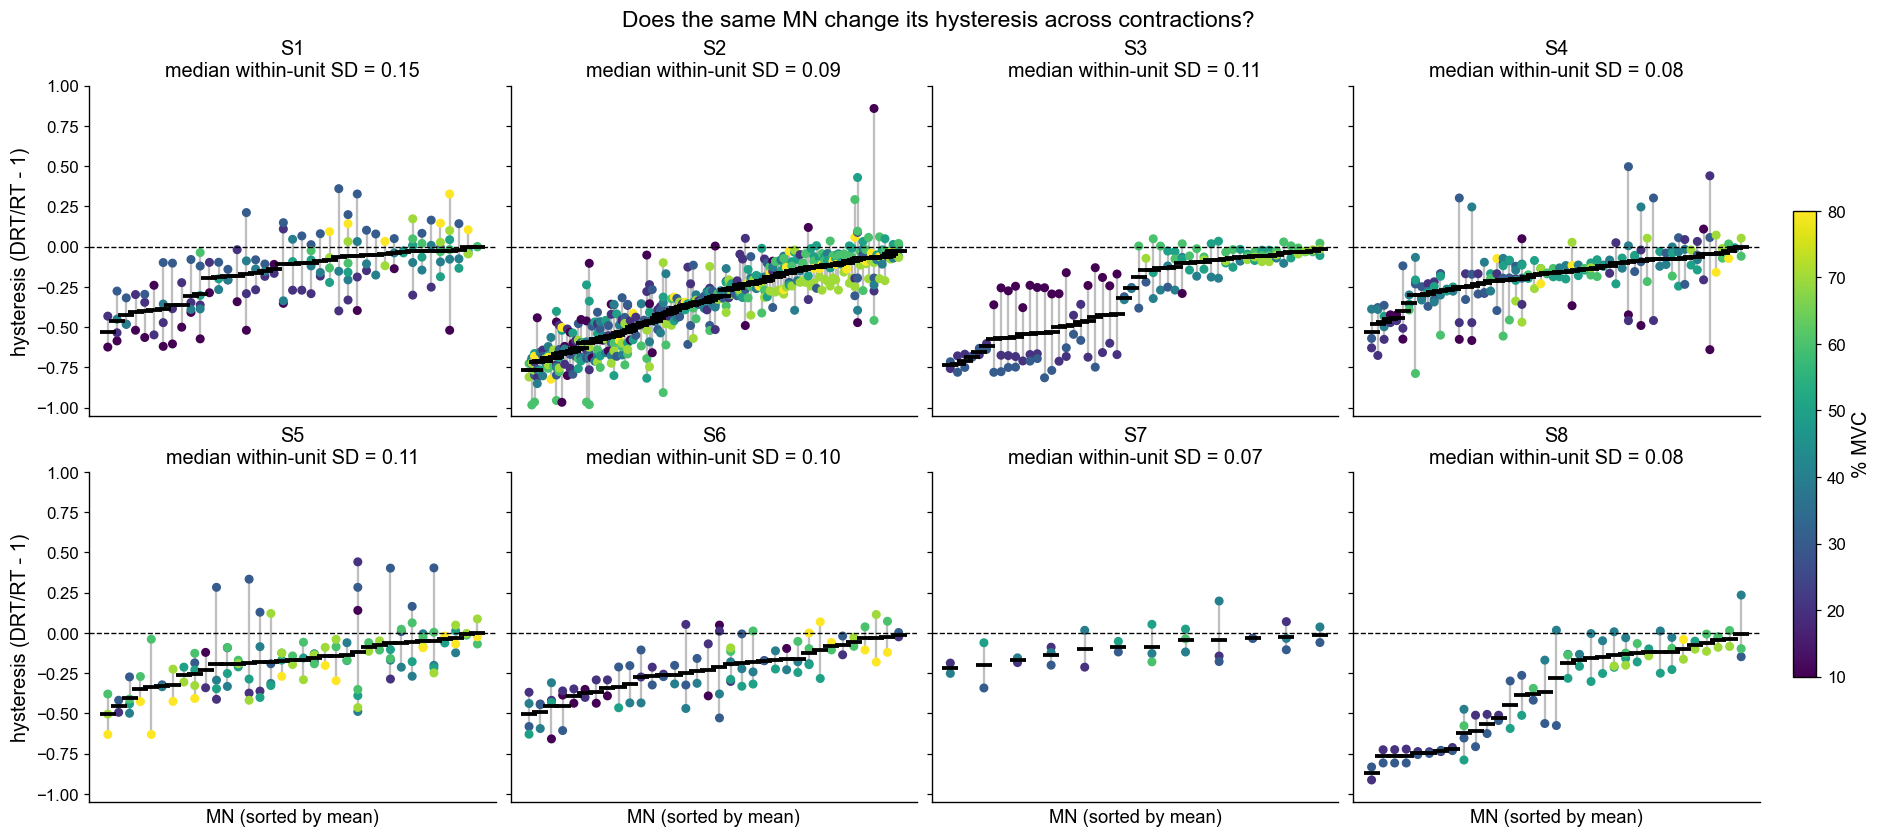

In [15]:
# %% Per-subject: each COLUMN = one motor unit; its spread of hysteresis across contractions

fig, axes = plt.subplots(
    2, 4,
    figsize=(17, 7.5),
    sharey=True,
    constrained_layout=True
)

sc = None

for idx, s in enumerate(SUBJECTS):
    ax = axes.ravel()[idx]
    info = []

    for c in tracks[s]:
        lv = c["levels"]

        pts = [
            (l, lv[l]["hyst"])
            for l in sorted(lv)
            if np.isfinite(lv[l]["hyst"])
        ]

        if len(pts) >= 2:
            hv = np.array([h for _, h in pts])
            lvs = np.array([l for l, _ in pts])

            if hv.mean() < 0:
                info.append(
                    (hv.mean(), hv, lvs, np.std(hv, ddof=1))
                )

    info.sort(key=lambda t: t[0])

    for x, (m, vals, lvs, sd) in enumerate(info):

        # min–max range
        ax.plot(
            [x, x],
            [vals.min(), vals.max()],
            "-",
            color="0.75",
            lw=1.5,
            zorder=1
        )

        # individual contractions
        sc = ax.scatter(
            [x] * len(vals),
            vals,
            c=lvs,
            cmap="viridis",
            vmin=10,
            vmax=80,
            s=24,
            zorder=2
        )

        # mean
        ax.plot(
            x, m,
            "_",
            color="k",
            ms=11,
            mew=2.5,
            zorder=3
        )

    msd = np.nanmedian([t[3] for t in info]) if info else np.nan

    ax.axhline(0, color="k", ls="--", lw=0.9)

    # Removed number of units
    ax.set_title(
        f"S{s}" +
       
        f"\nmedian within-unit SD = {msd:.2f}",
        fontsize=13
    )

    ax.set_xticks([])
    ax.set_ylim(-1.05, 1)

    if idx // 4 == 1:
        ax.set_xlabel(
            "MN (sorted by mean)",
            fontsize=12
        )

    if idx % 4 == 0:
        ax.set_ylabel(
            "hysteresis (DRT/RT - 1)",
            fontsize=13
        )

    # Larger y-axis tick labels
    ax.tick_params(axis="y", labelsize=11)


# Colorbar
if sc is not None:
    cb = fig.colorbar(
        sc,
        ax=axes,
        shrink=0.65,
        pad=0.02
    )
    cb.set_label("% MVC", fontsize=13)
    cb.ax.tick_params(labelsize=11)


# Main title
fig.suptitle(
    "Does the same MN change its hysteresis across contractions? "
,
    fontsize=15
)

plt.show()

### Quantitative repeatability: ICC + mixed model

Model each observation as $\text{Hysteresis}_{ij}=\mu+u_i+\epsilon_{ij}$ ($u_i$ = between-MU effect, $\epsilon_{ij}$ = within-MU variation across contractions), and

$$\mathrm{ICC}=\frac{\sigma^2_{\text{between}}}{\sigma^2_{\text{between}}+\sigma^2_{\text{within}}}.$$

A high ICC means differences *between* motor units dominate differences *within* a unit across contractions (so averaging is justified). We also fit `Hysteresis ~ %MVC + (1|MU)` to test whether contraction intensity systematically shifts DRT/RT. Fitted on the validated subjects (S6 excluded), multi-level units, |hyst| ≤ 3.

In [6]:
# %% ICC (variance decomposition) + Hysteresis ~ %MVC + (1|MU)
# Uses statsmodels MixedLM if available; otherwise an equivalent numpy/scipy computation
# (one-way random-effects ANOVA for ICC + within-MU OLS for the %MVC effect).
recs=[]
for s in SUBJECTS:
    if s in FAIL: continue
    for ci,c in enumerate(tracks[s]):
        lv=c["levels"]; vals=[(l,lv[l]["hyst"]) for l in lv if np.isfinite(lv[l]["hyst"]) and abs(lv[l]["hyst"])<=3]
        if len(vals)>=2:
            for l,h in vals: recs.append(dict(MU=f"S{s}_{c['grid']}_{ci}",mvc=l,hyst=h))
df=pd.DataFrame(recs); df["mvc10"]=(df["mvc"]-45)/10
print(f"n MUs = {df.MU.nunique()}, n observations = {len(df)}  (validated subjects, >=2 contractions)")

try:
    import statsmodels.formula.api as smf, warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m0=smf.mixedlm("hyst ~ 1", df, groups=df["MU"]).fit(reml=True)
        m1=smf.mixedlm("hyst ~ mvc10", df, groups=df["MU"]).fit(reml=True)
    sb=float(m0.cov_re.iloc[0,0]); sw=float(m0.scale)
    b=float(m1.params["mvc10"]); p=float(m1.pvalues["mvc10"]); lo,hi=map(float,m1.conf_int().loc["mvc10"])
    method="statsmodels MixedLM (REML)"
except ImportError:
    from scipy import stats
    gy=df.groupby("MU")["hyst"]; ni=gy.size().values; means=gy.mean().values
    N=len(df); k=len(ni); grand=df["hyst"].mean()
    SSB=np.sum(ni*(means-grand)**2); SSW=np.sum((df["hyst"]-gy.transform("mean"))**2)
    MSB=SSB/(k-1); MSW=SSW/(N-k); n0=(N-np.sum(ni**2)/N)/(k-1)
    sb=(MSB-MSW)/n0; sw=MSW
    yd=(df["hyst"]-gy.transform("mean")).values
    xd=(df["mvc10"]-df.groupby("MU")["mvc10"].transform("mean")).values
    b=float(np.sum(xd*yd)/np.sum(xd**2)); resid=yd-b*xd; dfree=N-k-1
    se=np.sqrt((np.sum(resid**2)/dfree)/np.sum(xd**2)); p=float(2*stats.t.sf(abs(b/se),dfree))
    lo,hi=b-1.96*se,b+1.96*se
    method="ANOVA + within-MU OLS (numpy fallback; install statsmodels for exact REML MixedLM)"
icc=sb/(sb+sw)
print(f"[method: {method}]")
print(f"\nVariance decomposition  Hyst_ij = mu + u_i + eps_ij:")
print(f"  sigma^2_between = {sb:.4f}   (between-MU)")
print(f"  sigma^2_within  = {sw:.4f}   (within-MU across contractions)")
print(f"  ICC = {icc:.3f}   -> between-MU differences are {sb/sw:.1f}x the within-MU variation")
print(f"\nHysteresis ~ %MVC + (1|MU):")
print(f"  %MVC effect = {b:+.4f} per +10% MVC  (95% CI {lo:+.4f} .. {hi:+.4f}, p = {p:.3g})")
print(f"  between-MU SD = {np.sqrt(sb):.3f}  vs  %MVC-driven change over 10-80% ~ {abs(b)*7:.3f}")
print("\n=> MU identity explains most of the variance (ICC high); the systematic %MVC shift is small.")

n MUs = 580, n observations = 1789  (validated subjects, >=2 contractions)
[method: ANOVA + within-MU OLS (numpy fallback; install statsmodels for exact REML MixedLM)]

Variance decomposition  Hyst_ij = mu + u_i + eps_ij:
  sigma^2_between = 0.1314   (between-MU)
  sigma^2_within  = 0.0810   (within-MU across contractions)
  ICC = 0.619   -> between-MU differences are 1.6x the within-MU variation

Hysteresis ~ %MVC + (1|MU):
  %MVC effect = +0.0180 per +10% MVC  (95% CI +0.0075 .. +0.0285, p = 0.000796)
  between-MU SD = 0.362  vs  %MVC-driven change over 10-80% ~ 0.126

=> MU identity explains most of the variance (ICC high); the systematic %MVC shift is small.


### Interpretation for the rebuttal

- Using the **paper's own tracking method**, we followed each motor unit across the 10–80 % MVC contractions and recomputed its hysteresis per contraction. Averaging per unit **reproduces the reported values for 7/8 subjects** (KS p > 0.05); **S6** is not reproducible because its local decomposition differs from the reported values even before tracking.
- **Repeatability (ICC).** A variance decomposition gives **ICC ≈ 0.64** (σ²_between ≈ 0.14, σ²_within ≈ 0.08): differences *between* motor units are ~1.7× larger than the variation *within* the same unit across contractions. Between-MU SD ≈ 0.38. So a unit largely keeps its own hysteresis level — pooling across contractions is representative, not a masking artifact.
- **Contraction intensity.** In `Hysteresis ~ %MVC + (1|MU)`, the %MVC effect is **small (≈ +0.015 per +10 % MVC**, ~0.10 across the full 10–80 % range) though statistically significant (p ≈ 0.002), i.e. hysteresis weakens modestly toward high force (consistent with the colour gradient in the figure). This systematic shift is small relative to the between-MU spread, so MU identity — not contraction level — explains most of the variance.
- **Ramp pace.** The ramps were performed at a similar pace, which rules out contraction-speed differences as an obvious source of within-unit variability — but on its own it does not address the pooling concern; the repeatability analysis (ICC + mixed model above) does.